# Basketball Action Recognition — Dataset Analysis

In [30]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import cv2  

# Directory paths setup
CURRENT_DIR = Path.cwd()
if (CURRENT_DIR / "dataset_hd").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "dataset_hd").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATASET_ROOT = PROJECT_ROOT / "dataset_hd"
MANIFEST_PATH = DATASET_ROOT / "manifest.csv"

print("Project root :", PROJECT_ROOT.resolve())
print("Dataset root :", DATASET_ROOT.resolve())
print("Manifest     :", MANIFEST_PATH.resolve())

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(f"Manifest non trovato: {MANIFEST_PATH}")

EXPECTED_CLASSES = [
    "passaggio",
    "tiroDaDue0",
    "tiroDaDue1",
    "tiroDaTre0",
    "tiroDaTre1",
    "tiroLibero0",
    "tiroLibero1",
    "idle",
    "non-gioco",
]
EXPECTED_SPLITS = [
    "train",
    "val",
    "test"]
REQUIRED_COLUMNS = [
    "clip_id",
    "path",
    "video_id",
    "start_time",
    "end_time",
    "label",
    "split",
]

Project root : C:\Users\fedeg\Desktop\universita\magistrale\Biometria\BasketAR_G1
Dataset root : C:\Users\fedeg\Desktop\universita\magistrale\Biometria\BasketAR_G1\dataset_hd
Manifest     : C:\Users\fedeg\Desktop\universita\magistrale\Biometria\BasketAR_G1\dataset_hd\manifest.csv


#### Dataset Manifest Loading & Initial Validation
Controllo anche dell'integrità
# ---------------------------------------------------------
# 2. VERIFICA INTEGRITÀ DATI
# ---------------------------------------------------------


In [32]:
df=pd.read_csv(MANIFEST_PATH)
df["duration"] = df["end_time"] - df["start_time"]

print(f"Total clip: {len(df)}")
print(f"Missing value (null):  {df.isnull().sum().sum()}")
print(f"Clip <= 0s:   {(df['duration'] <= 0).sum()}")

#  Data Leakage e Video distribution
train_videos = set(df[df["split"] == "train"]["video_id"].unique())
val_videos = set(df[df["split"] == "val"]["video_id"].unique())
test_videos = set(df[df["split"] == "test"]["video_id"].unique())

overlap_train_val = train_videos.intersection(val_videos)
overlap_train_test = train_videos.intersection(test_videos)
overlap_val_test = val_videos.intersection(test_videos)

print(f"Video in Train ({len(train_videos)}): {train_videos}")
print(f"Video in Val   ({len(val_videos)}): {val_videos}")
print(f"Video in Test  ({len(test_videos)}): {test_videos}")

if overlap_train_val or overlap_train_test or overlap_val_test:
    print("⚠️ ATTENZIONE: Trovato data leakage tra gli split!")
    if overlap_train_val: print(f"  - Train/Val overlap: {overlap_train_val}")
    if overlap_train_test: print(f"  - Train/Test overlap: {overlap_train_test}")
    if overlap_val_test: print(f"  - Val/Test overlap: {overlap_val_test}")
else:
    print("Correct split")

video_counts = df["video_id"].value_counts()
print(video_counts.to_string())


Total clip: 5721
Missing value (null):  0
Clip <= 0s:   0
Video in Train (4): {'psa_corato', 'video1', 'basket_2nd', 'prima_parte'}
Video in Val   (1): {'seconda_parte'}
Video in Test  (1): {'psa_converted'}
Correct split
video_id
video1           1402
psa_corato       1176
basket_2nd       1130
psa_converted     939
seconda_parte     540
prima_parte       534


## CLASS DISTRIBUTION BY SPLIT

In [33]:
ct = pd.crosstab(df["label"], df["split"], margins=True)
ct_pct = (
    pd.crosstab(df["label"], df["split"], normalize="columns") * 100
).round(2)

dist_df = pd.DataFrame()
for col in ["train", "val", "test", "All"]:
    if col in ct.columns:
        dist_df[f"{col}_count"] = ct[col]
        if col != "All":
            dist_df[f"{col}_%"] = ct_pct[col]

print(dist_df.to_string())


             train_count  train_%  val_count  val_%  test_count  test_%  All_count
label                                                                             
idle                 645    15.21         93  17.22         117   12.46        855
non-gioco           1177    27.75        170  31.48         156   16.61       1503
passaggio           1787    42.13        212  39.26         506   53.89       2505
tiroDaDue0           197     4.64         21   3.89          48    5.11        266
tiroDaDue1           128     3.02         11   2.04          50    5.32        189
tiroDaTre0           111     2.62         12   2.22          29    3.09        152
tiroDaTre1            46     1.08          3   0.56           9    0.96         58
tiroLibero0           62     1.46          7   1.30          13    1.38         82
tiroLibero1           89     2.10         11   2.04          11    1.17        111
All                 4242      NaN        540    NaN         939     NaN       5721


In [36]:
dur_stats = df.groupby("label")["duration"].agg(
    count="count",
    mean="mean",
    median="median",
    min="min",
    max="max",
    p5=lambda x: x.quantile(.5),
    p55=lambda x: x.quantile(.50),
    p95=lambda x: x.quantile(.95),
)
dur_stats = dur_stats.round(2)
dur_stats.columns = [
    "count",
    "mean",
    "median",
    "min",
    "max",
    "P5",
    "P50",
    "P95 ",
]
print(dur_stats.to_string())



             count  mean  median   min   max    P5   P50  P95 
label                                                         
idle           855  0.72    0.52  0.15  2.50  0.52  0.52  1.81
non-gioco     1503  2.24    2.21  0.22  5.00  2.21  2.21  3.45
passaggio     2505  0.50    0.47  0.15  2.01  0.47  0.47  0.88
tiroDaDue0     266  1.28    1.27  0.30  2.64  1.27  1.27  2.05
tiroDaDue1     189  1.33    1.26  0.33  2.77  1.26  1.26  2.14
tiroDaTre0     152  1.88    1.84  0.91  3.19  1.84  1.84  2.43
tiroDaTre1      58  1.75    1.71  0.99  3.51  1.71  1.71  2.12
tiroLibero0     82  1.88    1.91  0.57  2.98  1.91  1.91  2.62
tiroLibero1    111  1.70    1.57  1.10  3.67  1.57  1.57  2.75


# Clip ultra-brevi and skewness

In [37]:
short_clips = df[df["duration"] < 0.5]
print("\n---  Clip Ultra-Brevi (< 0.5s) ---")
print(
    f"Totale clip < 0.5s: {len(short_clips)} ({len(short_clips)/len(df)*100:.1f}% del totale)"
)
print(short_clips["label"].value_counts().to_string())
df.groupby("label")["duration"].skew()


---  Clip Ultra-Brevi (< 0.5s) ---
Totale clip < 0.5s: 1799 (31.4% del totale)
label
passaggio     1403
idle           381
tiroDaDue0       8
non-gioco        4
tiroDaDue1       3


label
idle           1.587310
non-gioco      0.250958
passaggio      1.515841
tiroDaDue0     0.325818
tiroDaDue1     0.827762
tiroDaTre0     0.354667
tiroDaTre1     2.869196
tiroLibero0   -0.152102
tiroLibero1    1.699226
Name: duration, dtype: float64

### Graphs

In [42]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})



# Grafico 1: Distribuzione delle classi per split

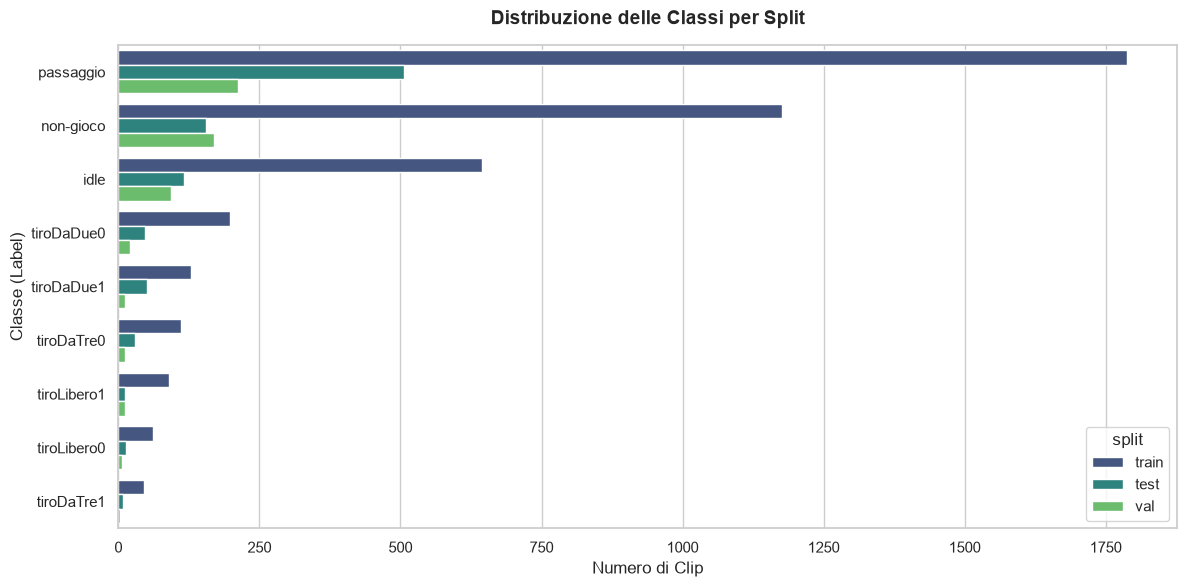

In [44]:

plt.figure(figsize=(12, 6))
class_order = df["label"].value_counts().index
sns.countplot(data=df, y="label", hue="split", order=class_order, palette="viridis")
plt.title("Distribuzione delle Classi per Split", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Numero di Clip", fontsize=12)
plt.ylabel("Classe (Label)", fontsize=12)
plt.tight_layout()

plt.show()


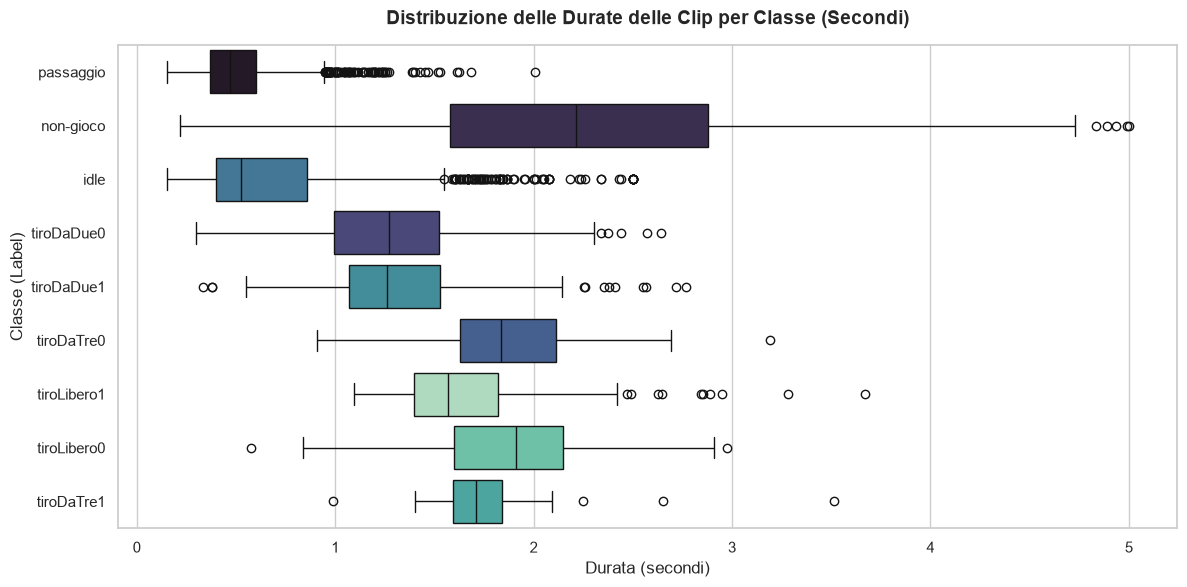

In [45]:
# Grafico 2: Boxplot delle durate delle clip per ogni classe
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="duration", y="label", order=class_order, palette="mako", hue="label", legend=False)
plt.title("Distribuzione delle Durate delle Clip per Classe (Secondi)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Durata (secondi)", fontsize=12)
plt.ylabel("Classe (Label)", fontsize=12)
plt.tight_layout()

plt.show()

Grafico 3: Distribuzione della durata in frame delle clip (Istogramma + KDE e Boxplot per classe)

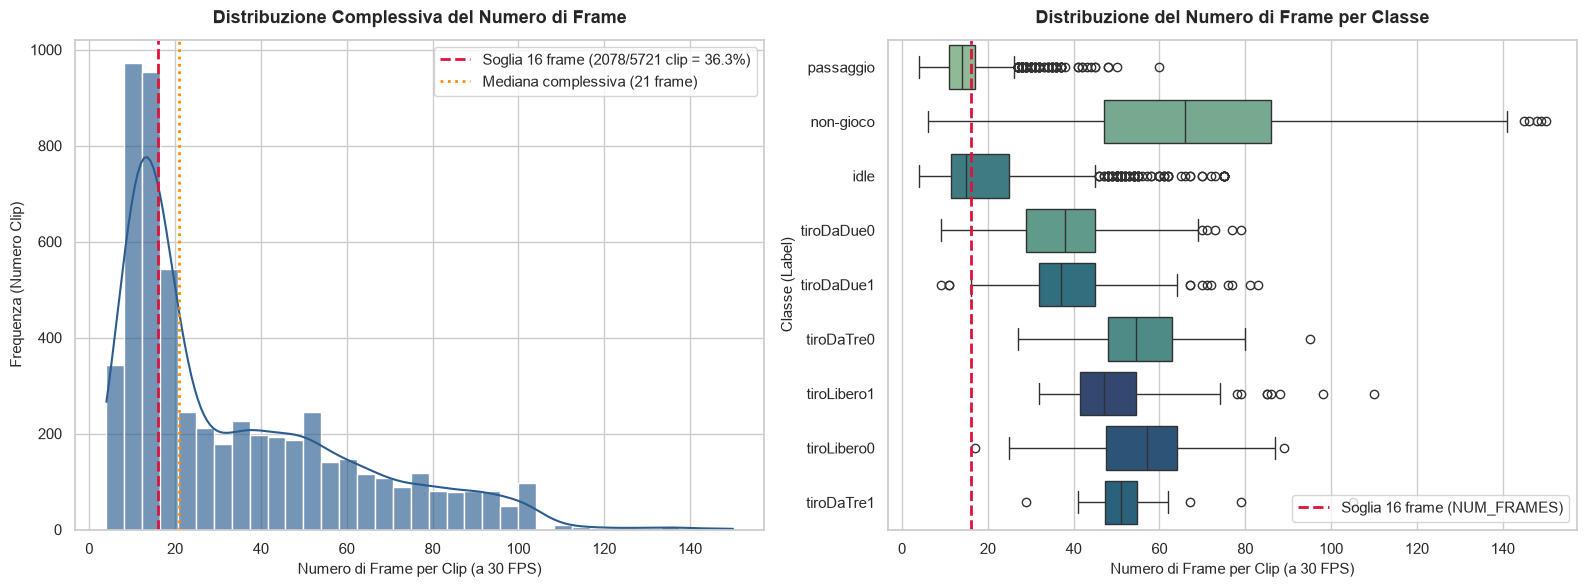

In [46]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot A: Istogramma e curva di densità KDE complessiva
sns.histplot(
    data=df,
    x="frame_count",
    kde=True,
    color="#2b5c8f",
    bins=35,
    ax=axes[0],
    edgecolor="white",
    alpha=0.65,
)
axes[0].axvline(
    x=16,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"Soglia 16 frame ({under_16_frames}/{len(df)} clip = {under_16_frames/len(df)*100:.1f}%)",
)
median_frames = df["frame_count"].median()
axes[0].axvline(
    x=median_frames,
    color="darkorange",
    linestyle=":",
    linewidth=2,
    label=f"Mediana complessiva ({median_frames:.0f} frame)",
)
axes[0].set_title("Distribuzione Complessiva del Numero di Frame", fontsize=13, fontweight="bold", pad=12)
axes[0].set_xlabel("Numero di Frame per Clip (a 30 FPS)", fontsize=11)
axes[0].set_ylabel("Frequenza (Numero Clip)", fontsize=11)
axes[0].legend(loc="upper right", frameon=True)

# Subplot B: Boxplot del frame count per classe
sns.boxplot(
    data=df,
    x="frame_count",
    y="label",
    order=class_order,
    palette="crest",
    hue="label",
    legend=False,
    ax=axes[1],
)
axes[1].axvline(
    x=16,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label="Soglia 16 frame (NUM_FRAMES)",
)
axes[1].set_title("Distribuzione del Numero di Frame per Classe", fontsize=13, fontweight="bold", pad=12)
axes[1].set_xlabel("Numero di Frame per Clip (a 30 FPS)", fontsize=11)
axes[1].set_ylabel("Classe (Label)", fontsize=11)
axes[1].legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()